# TechQuantum — Noyau quantique à 8 qubits pour classer les cultures marocaines

**Qiskit Fall Fest 2026 · EMSI Casablanca · Quantum Africa** — Équipe **TechQuantum**

**Tâche :** classer des parcelles de Doukkala en **luzerne, maïs ou blé** à partir de 13 mesures Sentinel-2 (B1…B12, NDVI).

**Notre question (une seule comparaison) :** à entrée, parcelles d'entraînement, classifieur (SVM) et budget de réglage identiques,
est-ce que remplacer un noyau classique (RBF, linéaire) par un **noyau de fidélité quantique à 8 qubits** change la macro-F1 de validation ?

| Étape | Contenu | Durée indicative |
|---|---|---|
| 1 | Chargement et vérification des données | < 5 s |
| 2 | Le modèle : circuit ZZ, noyau de fidélité, vérification contre Qiskit | ~ 10 s |
| 3 | Comparaison appariée quantique vs contrôles classiques (CV sur l'entraînement) | ~ 1,5 min |
| 4 | Concentration du noyau (choix de l'échelle) | ~ 2 min |
| 5 | Courbe d'apprentissage 25 / 50 / 100 % | ~ 2 min |
| 6 | Modèle final (`Submission`), graines 0/1/2, prédictions test | ~ 1 min |
| 7 | Conclusions et limites | — |

Tout tourne en **simulation exacte locale** (`Statevector`, sans tirs), sans compte IBM.

## 1. Données

Le chargeur fourni vérifie les empreintes SHA-256, les schémas et la séparation spatiale des jeux.

In [1]:
from pathlib import Path
import sys, json, time
ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import os; os.chdir(ROOT)

import numpy as np, pandas as pd
from IPython.display import display, Image
from challenge.data import load_data
from challenge.coverage import LABELS

tables, _, manifest, _ = load_data()
print('Classes      :', LABELS)
print('Lignes       :', manifest['rows'])
print('Variables    :', manifest['features'])
print('Entraînement :', tables['train'].target.value_counts().to_dict())
print('Validation   :', tables['validation'].target.value_counts().to_dict())

Classes      : ['alfalfa', 'maize', 'wheat']
Lignes       : {'train': 914, 'validation': 150, 'test': 221}
Variables    : ['B1', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B9', 'B11', 'B12', 'NDVI']
Entraînement : {'wheat': 425, 'alfalfa': 247, 'maize': 242}
Validation   : {'wheat': 50, 'maize': 50, 'alfalfa': 50}


## 2. Le modèle

1. **Prétraitement** (ajusté sur l'entraînement uniquement) : `StandardScaler → PCA(8) → StandardScaler`, 13 → 8 variables.
2. **Encodage quantique** : chaque parcelle *x* devient un état à 8 qubits $|\psi(x)\rangle = U_{ZZ}(s\cdot x)\,|0\rangle^{\otimes 8}$,
   avec la carte `zz_feature_map` (intrication linéaire, 2 répétitions) et une **échelle** *s*.
3. **Noyau de fidélité** : $K(x,x') = |\langle\psi(x)|\psi(x')\rangle|^2$.
4. **Classifieur** : SVM classique sur ce noyau précalculé.

Aucun angle n'est entraîné dans le circuit. On simule **un état par parcelle** puis on fait des produits scalaires,
au lieu d'une simulation par paire ou par pas d'optimiseur. C'est pour cela que ce modèle est beaucoup plus rapide que le QNN de départ.

Une répétition du circuit (le modèle en empile deux) :

saved fig0_circuit


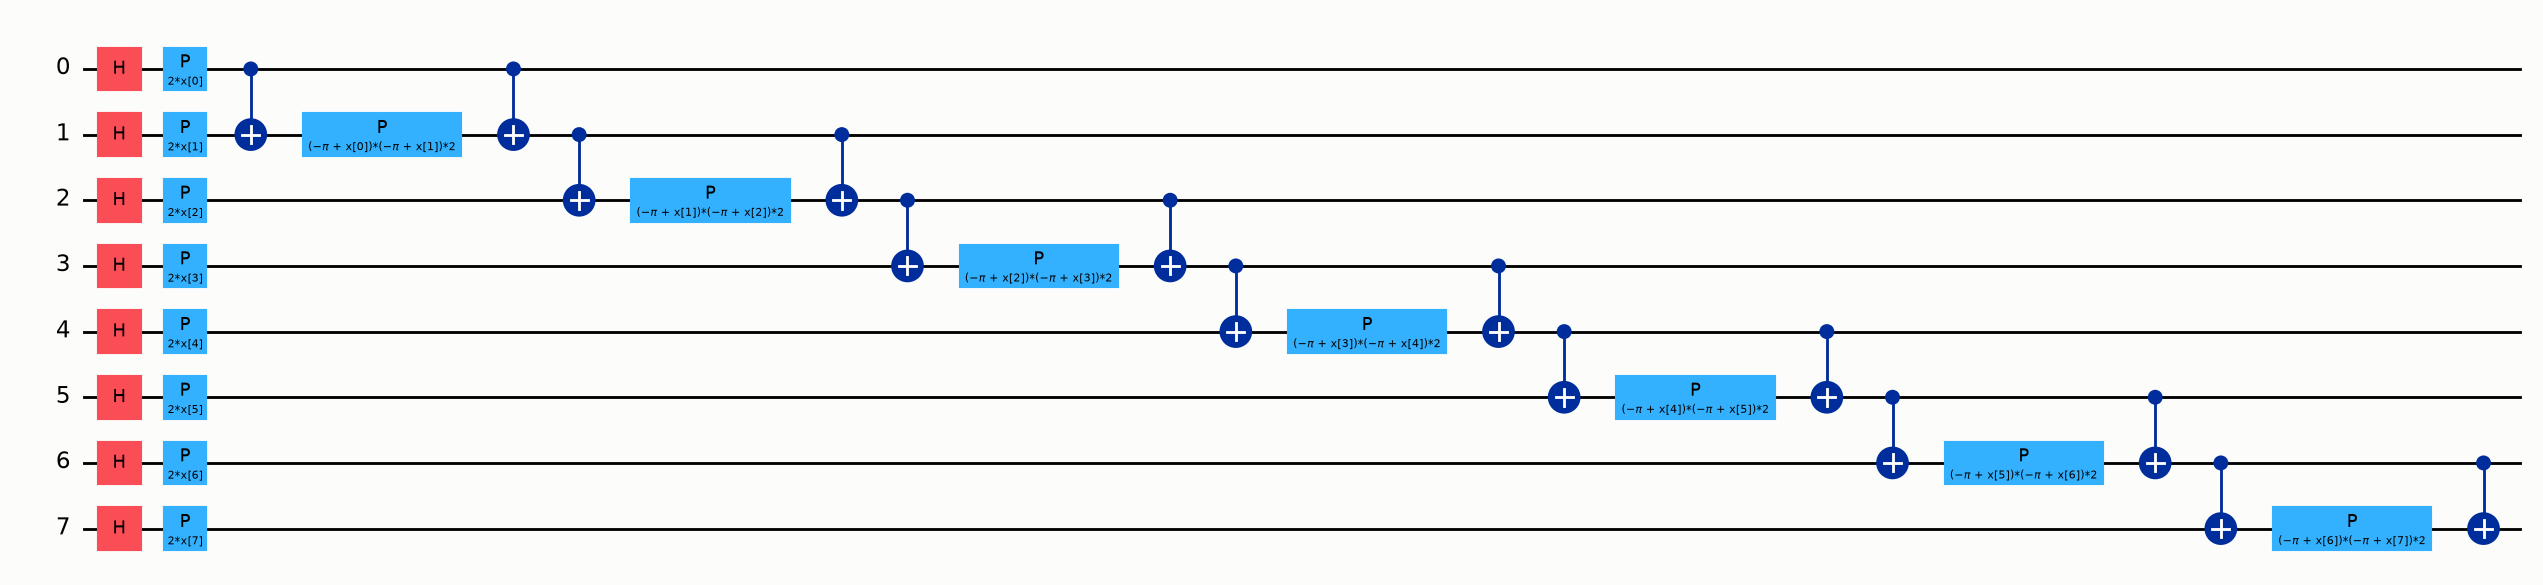

Qubits: 8 | profondeur: 31 | portes 2 qubits: 28 | paramètres entraînables du circuit: 0


In [2]:
from experiments.step3_figures import fig_circuit, OUT as FIG
FIG.mkdir(parents=True, exist_ok=True); fig_circuit()
display(Image(filename=str(FIG / 'fig0_circuit.png'), width=900))

from challenge.quantum_kernel import feature_map, encode, fidelity
c = feature_map(8, reps=2).decompose()
print('Qubits:', c.num_qubits, '| profondeur:', c.depth(), '| portes 2 qubits:', sum(len(i.qubits)==2 for i in c.data),
      '| paramètres entraînables du circuit: 0')

**Vérification :** notre calcul du noyau doit être identique à l'implémentation officielle de Qiskit `FidelityStatevectorKernel`.

In [3]:
from qiskit_machine_learning.kernels import FidelityStatevectorKernel
with np.load(ROOT / 'data/views/pca8.npz', allow_pickle=False) as f: X8 = f['X_train'][:30]
fm, s = feature_map(8, reps=2), 0.04
S = encode(X8, s, fm)
diff = np.abs(fidelity(S, S) - FidelityStatevectorKernel(feature_map=fm).evaluate(s * X8)).max()
print(f'Écart maximal avec Qiskit : {diff:.1e}'); assert diff < 1e-10

Écart maximal avec Qiskit : 6.9e-15


## 3. Comparaison appariée : noyau quantique vs contrôles classiques

| | Noyau quantique ZZ | Contrôle RBF | Contrôle linéaire |
|---|---|---|---|
| Entrée | pca8 | pca8 | pca8 |
| Classifieur | SVM | SVM | SVM |
| Réglages essayés | 5 échelles × 5 C = 25 | 5 γ × 5 C = 25 | 5 C |
| Sélection | CV stratifiée 5 plis sur l'entraînement | idem | idem |

La validation n'est utilisée **qu'une fois** par modèle sélectionné. Le SVM de référence fourni (13 variables) est donné pour contexte.
La grille quantique a été réglée en deux tours, tous deux sur la CV d'entraînement : le premier tour (échelles 0,1–0,8) choisissait sa valeur au bord, donc nous l'avons décalée (voir section 4).
Les différences sont testées par **bootstrap apparié sur les blocs spatiaux** de validation (2 000 tirages).

scale 0.02: off-diagonal kernel mean 0.840 std 0.129


scale 0.04: off-diagonal kernel mean 0.558 std 0.232


scale 0.07: off-diagonal kernel mean 0.260 std 0.230


scale 0.1: off-diagonal kernel mean 0.124 std 0.175


scale 0.15: off-diagonal kernel mean 0.046 std 0.104


             bandwidth      C     cv_f1     cv_sd
model                                            
linear_pca8        NaN   10.0  0.897208  0.025419
quantum_zz        0.04  100.0  0.910606  0.025794
rbf_pca8          0.03   10.0  0.915741  0.023750



Validation (150 fields):
quantum_zz       macro-F1 0.8864  acc 0.8867  recall [0.92 0.9  0.84]  fit 7.96s
rbf_pca8         macro-F1 0.9064  acc 0.9067  recall [0.94 0.92 0.86]  fit 0.02s
linear_pca8      macro-F1 0.9126  acc 0.9133  recall [0.94 0.96 0.84]  fit 0.07s
reference_svm13  macro-F1 0.8797  acc 0.8800  recall [0.94 0.86 0.84]  fit 0.09s
quantum_zz - rbf_pca8            dF1 -0.0200  95% CI [-0.0669, +0.0212]
quantum_zz - linear_pca8         dF1 -0.0262  95% CI [-0.0750, +0.0130]
quantum_zz - reference_svm13     dF1 +0.0066  95% CI [-0.0361, +0.0463]

Durée : 81 s


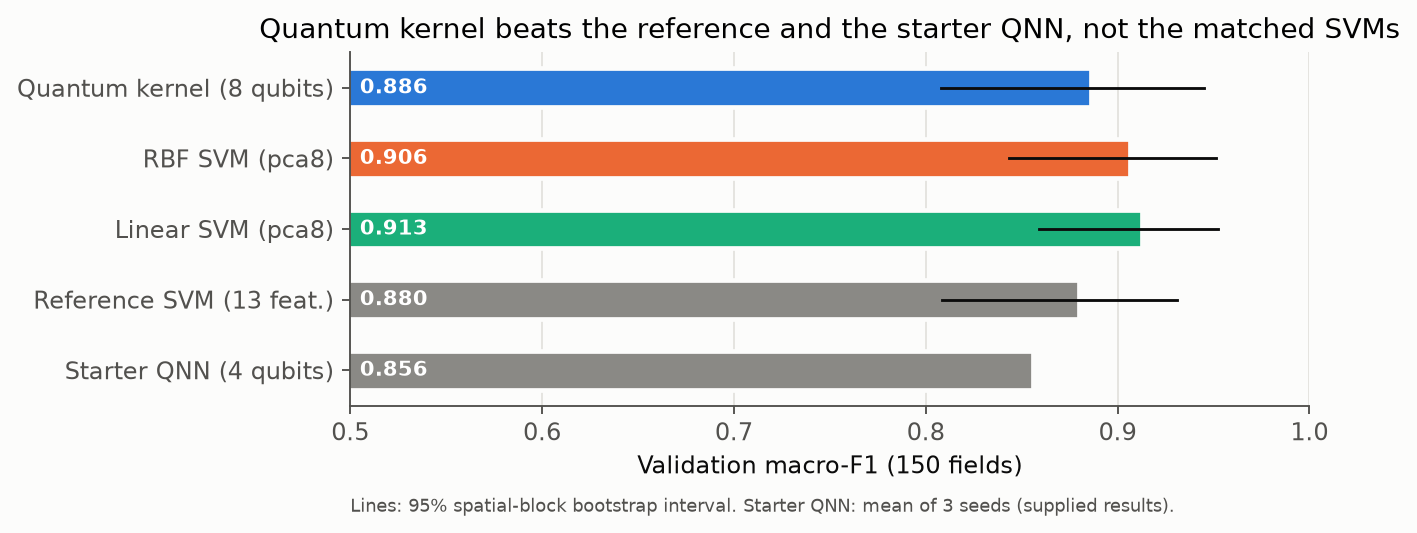

In [4]:
from experiments import step2_quantum_kernel
t = time.perf_counter(); step2_quantum_kernel.main(); print(f'\nDurée : {time.perf_counter()-t:.0f} s')
display(Image(filename=str(FIG / 'fig2_validation_scores.png'), width=750)) if (FIG / 'fig2_validation_scores.png').exists() else None

## 4. Concentration du noyau : pourquoi l'échelle compte

Quand l'échelle d'encodage grandit, les états de deux parcelles différentes deviennent presque orthogonaux :
leur similarité tombe vers $1/2^8 = 1/256$. Le noyau ressemble alors à la matrice identité et le SVM ne peut plus généraliser.
C'est la **concentration exponentielle** des noyaux quantiques. Ce balayage utilise uniquement la CV sur l'entraînement.

saved fig1_kernel_bandwidth


,scale,offdiag_mean,offdiag_std,cv_f1,cv_sd
0,0.02,0.840,0.129,0.908,0.029
1,0.04,0.558,0.232,0.911,0.026
2,0.07,0.260,0.230,0.906,0.020
3,0.10,0.124,0.175,0.903,0.026
4,0.15,0.046,0.104,0.888,0.028
5,0.20,0.020,0.064,0.860,0.030
6,0.30,0.007,0.028,0.817,0.023
7,0.50,0.005,0.012,0.564,0.040
8,0.80,0.005,0.009,0.359,0.040


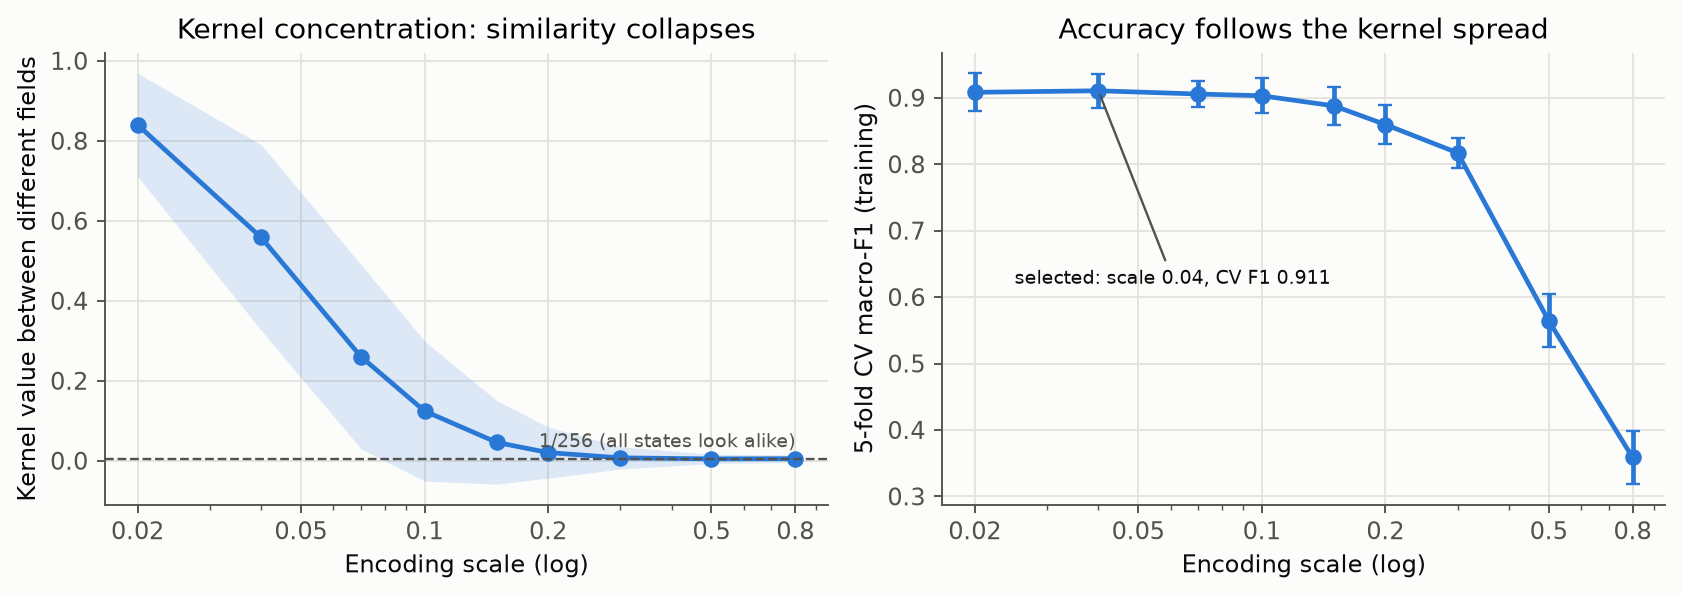

In [5]:
from experiments import step3_figures
step3_figures.fig_bandwidth()
display(pd.read_csv(FIG / 'bandwidth_sweep.csv').round(3))
display(Image(filename=str(FIG / 'fig1_kernel_bandwidth.png'), width=900))

## 5. Courbe d'apprentissage

Pour 25 %, 50 % et 100 % des 914 parcelles, et pour les graines 0/1/2 (tirage du sous-ensemble), on réajuste le prétraitement sur le sous-ensemble,
puis on entraîne les trois modèles **sur exactement les mêmes lignes**. Les réglages restent ceux de la section 3.

quantum_zz   n=228 seed=0  macro-F1 0.8801  fit 0.9s
rbf_pca8     n=228 seed=0  macro-F1 0.9139  fit 0.0s
linear_pca8  n=228 seed=0  macro-F1 0.9071  fit 0.0s


quantum_zz   n=228 seed=1  macro-F1 0.8064  fit 0.9s
rbf_pca8     n=228 seed=1  macro-F1 0.8864  fit 0.0s
linear_pca8  n=228 seed=1  macro-F1 0.8336  fit 0.0s


quantum_zz   n=228 seed=2  macro-F1 0.8452  fit 0.9s
rbf_pca8     n=228 seed=2  macro-F1 0.9201  fit 0.0s
linear_pca8  n=228 seed=2  macro-F1 0.8737  fit 0.0s


quantum_zz   n=457 seed=0  macro-F1 0.8930  fit 1.9s
rbf_pca8     n=457 seed=0  macro-F1 0.9133  fit 0.0s
linear_pca8  n=457 seed=0  macro-F1 0.8868  fit 0.0s


quantum_zz   n=457 seed=1  macro-F1 0.8932  fit 2.0s
rbf_pca8     n=457 seed=1  macro-F1 0.9000  fit 0.0s
linear_pca8  n=457 seed=1  macro-F1 0.8925  fit 0.0s


quantum_zz   n=457 seed=2  macro-F1 0.8798  fit 1.8s
rbf_pca8     n=457 seed=2  macro-F1 0.9204  fit 0.0s
linear_pca8  n=457 seed=2  macro-F1 0.8928  fit 0.0s


quantum_zz   n=914 seed=0  macro-F1 0.8864  fit 3.8s
rbf_pca8     n=914 seed=0  macro-F1 0.9064  fit 0.0s
linear_pca8  n=914 seed=0  macro-F1 0.9126  fit 0.0s


quantum_zz   n=914 seed=1  macro-F1 0.8864  fit 3.6s
rbf_pca8     n=914 seed=1  macro-F1 0.9064  fit 0.0s
linear_pca8  n=914 seed=1  macro-F1 0.9126  fit 0.0s


quantum_zz   n=914 seed=2  macro-F1 0.8864  fit 3.6s
rbf_pca8     n=914 seed=2  macro-F1 0.9064  fit 0.0s
linear_pca8  n=914 seed=2  macro-F1 0.9126  fit 0.0s

       model  n_train  macro_f1_mean  macro_f1_sd  accuracy_mean  fit_seconds_mean
linear_pca8      228       0.871478     0.030074       0.871111          0.004226
linear_pca8      457       0.890672     0.002758       0.891111          0.017356
linear_pca8      914       0.912616     0.000000       0.913333          0.037950
 quantum_zz      228       0.843901     0.030107       0.844444          0.903711
 quantum_zz      457       0.888667     0.006277       0.888889          1.888410
 quantum_zz      914       0.886368     0.000000       0.886667          3.668102
   rbf_pca8      228       0.906805     0.014628       0.906667          0.002247
   rbf_pca8      457       0.911228     0.008459       0.911111          0.006862
   rbf_pca8      914       0.906373     0.000000       0.906667          0.015844


saved fig4_learning_curve


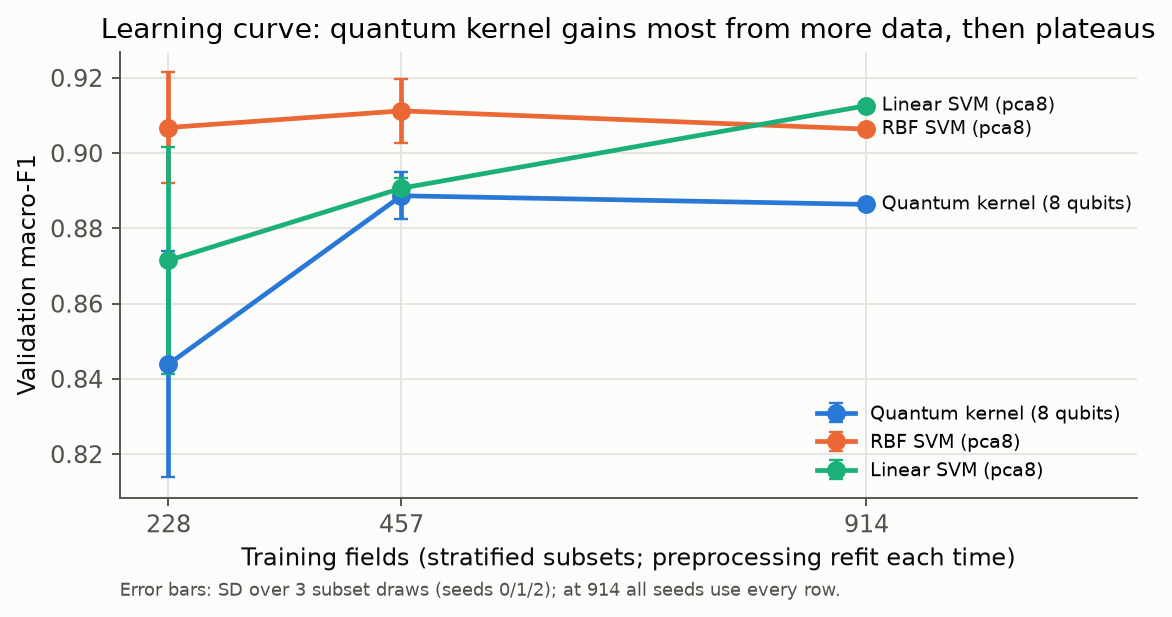

In [6]:
from experiments import step3_learning_curve
step3_learning_curve.main()
step3_figures.fig_learning()
display(Image(filename=str(FIG / 'fig4_learning_curve.png'), width=650))

## Figures de synthèse : erreurs par classe et temps de calcul

saved fig2_validation_scores


saved fig3_confusion


saved fig5_runtime


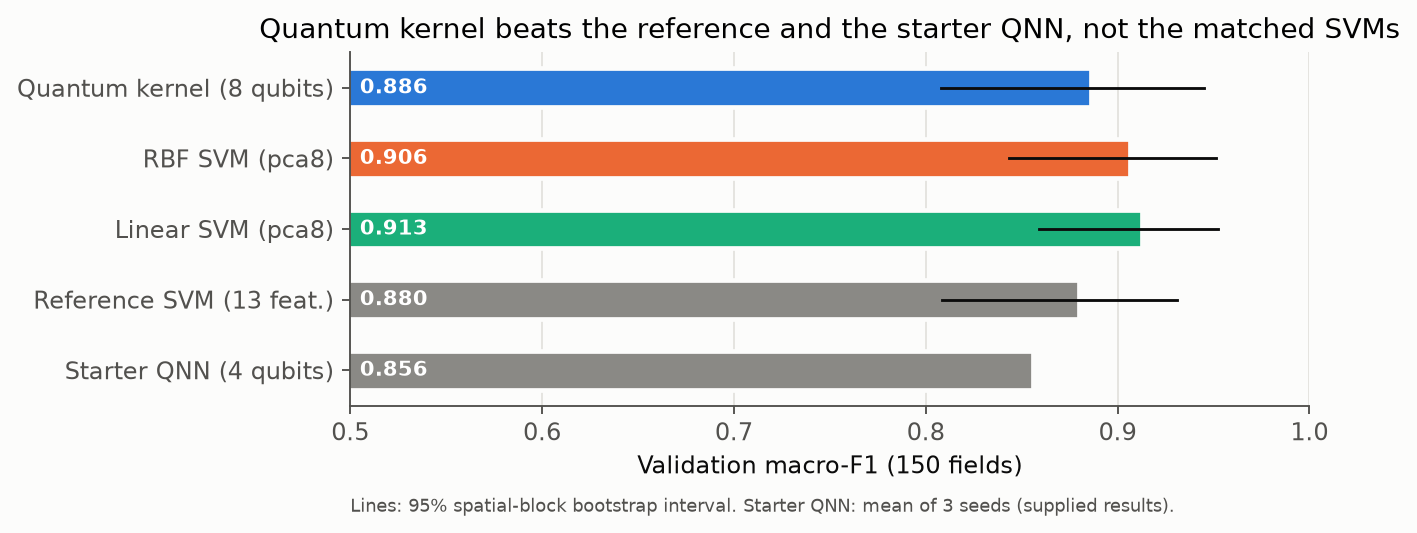

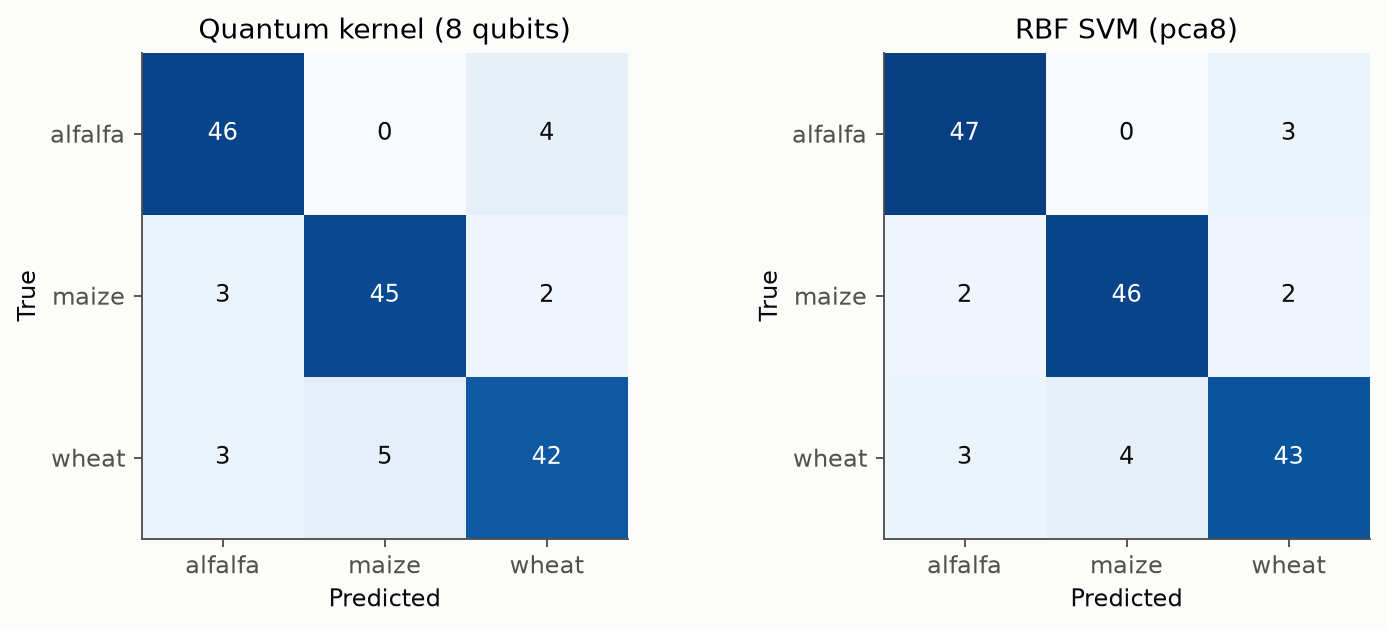

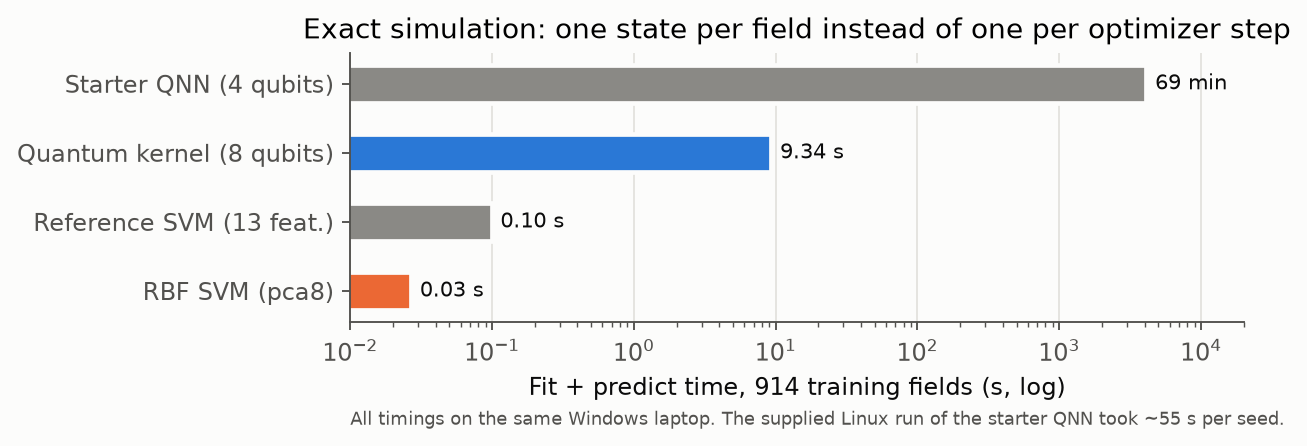

In [7]:
step3_figures.fig_validation(); step3_figures.fig_confusion(); step3_figures.fig_runtime()
for name in ['fig2_validation_scores', 'fig3_confusion', 'fig5_runtime']:
    display(Image(filename=str(FIG / f'{name}.png'), width=750))

## 6. Modèle final et prédictions test

`challenge.submission.Submission` contient tout le workflow (13 variables brutes → PCA 8 → noyau quantique → SVM), avec les réglages de
`configs/techquantum.json`. Le modèle est **déterministe** : les graines 0/1/2 donnent des résultats identiques, ce que le script vérifie.
Il vérifie aussi que `Submission` reproduit exactement les prédictions de validation de la section 3.

In [8]:
from experiments import predict_test
predict_test.main()
runs = json.loads((ROOT / 'outputs/final/runs.json').read_text())
r = runs[0]; m = r['validation']
print('\nRessources :', r['resources'])
display(pd.DataFrame({'précision': m['precision'], 'rappel': m['recall'], 'support': m['support']}, index=LABELS).round(3))
display(pd.read_csv(ROOT / 'outputs/final/test_predictions.csv').head())

seed 0: validation macro-F1 0.8864  fit 3.7s  predict 1.5s


seed 1: validation macro-F1 0.8864  fit 3.7s  predict 1.5s


seed 2: validation macro-F1 0.8864  fit 3.7s  predict 1.4s


test class counts: {'alfalfa': np.int64(55), 'maize': np.int64(65), 'wheat': np.int64(101)}

Ressources : {'qubits': 8, 'trainable_quantum': 0, 'depth': 31, 'two_qubit_gates': 28, 'feature_map': 'ZZ reps=2 linear', 'scale': 0.04, 'C': 100.0, 'circuit_simulations_fit': 914, 'support_vectors': 202, 'kernel_entries': 835396, 'encode_seconds': 3.6288002000073902}


,précision,rappel,support
alfalfa,0.885,0.92,50
maize,0.900,0.90,50
wheat,0.875,0.84,50


,sample_id,prediction
0,r2_20ee84e282b608b9,maize
1,r2_3f59edc42ae9243f,maize
2,r2_40d69d894813f204,wheat
3,r2_278ee6f93f7b31ef,maize
4,r2_653d9a22fd070481,maize


## 7. Conclusions et limites

**Ce que nous observons (validation, 150 parcelles) :**
- Le noyau quantique à 8 qubits atteint **0,886 de macro-F1**. C'est mieux que le QNN de départ (0,856) et du même niveau que le SVM de référence (0,880).
- Il reste **en dessous des contrôles classiques appariés** sur les mêmes 8 variables (RBF 0,906, linéaire 0,913).
  Les écarts ne sont **pas significatifs** au bootstrap spatial (les intervalles à 95 % contiennent 0) : nos données ne montrent **aucun avantage quantique**.
- **Concentration du noyau :** au-delà d'une échelle de 0,2, la similarité moyenne tend vers 1/256 et la macro-F1 de CV chute de 0,91 à 0,36.
  Le bon régime est une faible échelle, où le noyau ZZ se comporte comme un noyau classique lisse, ce qui explique des performances proches du RBF.
- **Données :** le noyau quantique gagne beaucoup entre 228 et 457 parcelles, puis plafonne. Le RBF est déjà bon avec 228.
- **Coût :** environ 15 s par graine sur un ordinateur portable, contre 69 min pour le QNN de départ sur la même machine.

**Limites :**
- Une seule cohorte locale (Doukkala, une date d'image) ; les étiquettes sont supposées valables à ±2 jours.
- La CV d'entraînement n'est pas spatiale : les plis peuvent partager des voisinages et surestimer les scores de CV (la validation, elle, est séparée spatialement).
- Les graines ne décrivent pas d'incertitude pour un modèle déterministe ; l'incertitude vient du bootstrap spatial.
- Simulation exacte uniquement ; le bruit d'un vrai processeur n'est pas étudié ici.

**Reproductibilité :** Python 3.12, `requirements.txt` figé (Qiskit 2.4.2, qiskit-machine-learning 0.9.1). Sous Windows, cloner avec `git config core.autocrlf false`
pour que les empreintes des données restent valides.

**Code et méthodes réutilisés :** chargeur, métriques, SVM de référence et bootstrap spatial fournis par le dépôt du challenge (Quantum Africa) ;
carte de caractéristiques ZZ de Qiskit ; méthode du noyau quantique d'après Havlíček et al., *Nature* 567 (2019).
Données : Ouassanouan et al., *Moroccan Crop and Irrigation Dataset v2* (CC BY 4.0).